In [113]:
#import

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

RANDOM_STATE = 333
TEST_SIZE = 0.30

print("Random state:", RANDOM_STATE)


Random state: 333


In [114]:
#dataset

DATA_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/statlog/german/german.data"
)

DATA_FILE = "german.data"

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

columns = [
    "checking_status", "duration", "credit_history", "purpose",
    "credit_amount", "savings_status", "employment",
    "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age",
    "other_installment_plans", "housing", "existing_credits",
    "job", "num_dependents", "telephone", "foreign_worker",
    "credit_class"
]

df = pd.read_csv(
    DATA_FILE,
    sep=r"\s+",
    header=None,
    names=columns
)

df["approval"] = (df["credit_class"] == 1).astype(int)
df.drop(columns=["credit_class"], inplace=True)

print("Dataset shape:", df.shape)
display(df.head())

print("\nApproval counts:")
print(df["approval"].value_counts())


Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,approval
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,0



Approval counts:
approval
1    700
0    300
Name: count, dtype: int64


In [115]:
#missing values

print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

numeric_columns = df.select_dtypes(
    include=np.number
).columns.drop("approval")

outlier_results = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

display(pd.DataFrame(outlier_results))


Missing values in each column:


,Missing Values
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings_status,0
employment,0
installment_rate,0
personal_status_sex,0
other_debtors,0


,Feature,Lower Bound,Upper Bound,Outlier Count
0,duration,-6.000,42.000,70
1,credit_amount,-2544.625,7882.375,72
2,installment_rate,-1.000,7.000,0
3,residence_since,-1.000,7.000,0
4,age,4.500,64.500,23
5,existing_credits,-0.500,3.500,6
6,num_dependents,1.000,1.000,155


In [116]:
#split into train and test

X = df.drop(columns=["approval"])
y = df["approval"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=333,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training percentage:",
      round(len(X_train) / len(df) * 100, 2))

print("Testing percentage:",
      round(len(X_test) / len(df) * 100, 2))


Training samples: 700
Testing samples: 300
Training percentage: 70.0
Testing percentage: 30.0


In [117]:
#encode categorical features nd scale numerical features

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])


preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (700, 48)
Processed testing shape: (300, 48)



## Data Preprocessing

### 1. Missing Values
The dataset was checked for missing values before model training. Numeric and categorical features were prepared using the preprocessing pipeline. Numeric columns use median imputation, while categorical columns use most-frequent-value imputation. This ensures that missing entries do not prevent the models from being trained.

### 2. Categorical Encoding
Categorical features were converted into numerical representations using one-hot encoding. The `handle_unknown="ignore"` setting allows the pipeline to process categories that were not encountered during training without producing an encoding error.

### 3. Feature Scaling
Numeric features were standardized using `StandardScaler`. The scaler was fitted on the training data and then applied to the test data, preventing information from the test set from influencing the scaling parameters.

### 4. Outlier Detection and Handling
Potential outliers were identified using the interquartile range (IQR) rule. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR were considered potential outliers. These values were inspected but not automatically removed or capped, because extreme credit amounts or loan durations may contain meaningful information. Their influence should be considered when interpreting the model results.


In [118]:
#Model A Linear Regression

X_train_ols = sm.add_constant(
    X_train_processed,
    has_constant="add"
)

X_test_ols = sm.add_constant(
    X_test_processed,
    has_constant="add"
)

ols_model = sm.OLS(
    y_train,
    X_train_ols
).fit()

ols_predictions = ols_model.predict(X_test_ols)

ols_threshold = np.median(ols_predictions)

ols_classes = (
    ols_predictions >= ols_threshold
).astype(int)

print(ols_model.summary())

print("\nMedian OLS prediction threshold:",
      round(float(ols_threshold), 4))

print("First 10 OLS predictions:")
print(ols_predictions.head(10))


                            OLS Regression Results                            
Dep. Variable:               approval   R-squared:                       0.320
Model:                            OLS   Adj. R-squared:                  0.270
Method:                 Least Squares   F-statistic:                     6.388
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           7.44e-31
Time:                        11:11:15   Log-Likelihood:                -311.95
No. Observations:                 700   AIC:                             721.9
Df Residuals:                     651   BIC:                             944.9
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [119]:
#Model B Logistic Regression

logistic_model = LogisticRegression(
    max_iter=3000,
    solver="liblinear",
    random_state=333
)

logistic_model.fit(
    X_train_processed,
    y_train
)

logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_classes = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, logistic_classes), 4))

print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, logistic_probabilities), 4))


Logistic Regression Accuracy: 0.72
Logistic Regression ROC-AUC: 0.7398


In [120]:
#Compare both models and calculate mismatches

comparison_df = pd.DataFrame({
    "Actual Approval": y_test.to_numpy(),
    "OLS Prediction": np.asarray(ols_predictions),
    "OLS Classification": np.asarray(ols_classes),
    "Logistic Probability": logistic_probabilities,
    "Logistic Classification": logistic_classes
}, index=y_test.index)

comparison_df["Mismatch"] = (
    comparison_df["OLS Classification"]
    != comparison_df["Logistic Classification"]
)

cm = confusion_matrix(
    comparison_df["OLS Classification"],
    comparison_df["Logistic Classification"],
    labels=[0, 1]
)

print("Confusion Matrix")
print("Rows = OLS classes; Columns = Logistic classes")
print(cm)

mismatch_count = int(comparison_df["Mismatch"].sum())
mismatch_percentage = (
    mismatch_count / len(comparison_df)
) * 100

print("\nTotal mismatches:", mismatch_count)
print("Total test cases:", len(comparison_df))
print("Mismatch percentage:",
      round(mismatch_percentage, 2), "%")

display(comparison_df.head(10))


Confusion Matrix
Rows = OLS classes; Columns = Logistic classes
[[ 60  90]
 [  0 150]]

Total mismatches: 90
Total test cases: 300
Mismatch percentage: 30.0 %


,Actual Approval,OLS Prediction,OLS Classification,Logistic Probability,Logistic Classification,Mismatch
366,1,1.161796,1,0.984889,1,False
80,0,0.993718,1,0.969960,1,False
226,0,0.441260,0,0.512888,1,True
818,1,-0.061059,0,0.044748,0,False
351,0,0.934206,1,0.925181,1,False
149,1,1.093328,1,0.977862,1,False
194,0,0.675655,0,0.670844,1,True
708,1,0.623251,0,0.605802,1,True
200,1,0.992244,1,0.954851,1,False
196,1,1.138935,1,0.984654,1,False


In [121]:
#Part 1 Final Results

comparison_df.to_csv(
    "part1_model_comparison.csv",
    index=True
)

coefficients_df = pd.DataFrame({
    "Feature": feature_names,
    "OLS Coefficient": ols_model.params.iloc[1:].to_numpy(),
    "Logistic Coefficient": logistic_model.coef_[0]
})

coefficients_df.to_csv(
    "part1_coefficients.csv",
    index=False
)

display(coefficients_df.head(10))

print("Part 1 results saved successfully.")


,Feature,OLS Coefficient,Logistic Coefficient
0,numeric__duration,-0.059879,-0.357343
1,numeric__credit_amount,-0.072788,-0.481375
2,numeric__installment_rate,-0.066964,-0.495076
3,numeric__residence_since,-0.015790,-0.103773
4,numeric__age,0.019236,0.177088
5,numeric__existing_credits,-0.016017,-0.095341
6,numeric__num_dependents,-0.013960,-0.110199
7,categorical__checking_status_A12,0.140072,0.658762
8,categorical__checking_status_A13,0.175147,0.671436
9,categorical__checking_status_A14,0.285659,1.724262


Part 1 results saved successfully.


In [122]:

# Part 2.1 — Simpson's Paradox Hunt
# Cell 10: Create gender subgroups

# In the German Credit dataset:
# A91 = male: divorced/separated
# A92 = female: divorced/separated/married
# A93 = male: single
# A94 = male: married/widowed
# A95 = female: single

df["gender_group"] = df["personal_status_sex"].map(
    lambda x: "Female" if x in ["A92", "A95"] else "Male"
)

print("Gender group counts:")
display(df["gender_group"].value_counts().to_frame("Count"))

print("\nApproval rate by gender:")
display(
    df.groupby("gender_group")["approval"]
      .agg(["count", "mean"])
      .rename(columns={"mean": "approval_rate"})
)


Gender group counts:


,Count
gender_group,
Male,690
Female,310



Approval rate by gender:


,count,approval_rate
gender_group,,
Female,310,0.648387
Male,690,0.723188


In [123]:

# Part 2.1 — Cell 11: Logistic Regression subgroup analysis
# Calculate coefficients, 95% confidence intervals, and p-values

import statsmodels.api as sm
import pandas as pd
import numpy as np

def fit_group_logistic(data, predictor="credit_amount"):
    X_group = sm.add_constant(
        data[[predictor]].astype(float),
        has_constant="add"
    )
    y_group = data["approval"].astype(int)

    fitted_model = sm.Logit(y_group, X_group).fit(disp=False)

    ci = fitted_model.conf_int().loc[predictor]

    return {
        "Sample Size": len(data),
        "Coefficient": fitted_model.params[predictor],
        "95% CI Lower": ci.iloc[0],
        "95% CI Upper": ci.iloc[1],
        "p-value": fitted_model.pvalues[predictor]
    }

male_data = df[df["gender_group"] == "Male"].copy()
female_data = df[df["gender_group"] == "Female"].copy()

full_result = fit_group_logistic(df)
male_result = fit_group_logistic(male_data)
female_result = fit_group_logistic(female_data)

coef_comparison = pd.DataFrame([
    {"Group": "Full dataset", **full_result},
    {"Group": "Male", **male_result},
    {"Group": "Female", **female_result}
])

display(coef_comparison.round(8))

coef_comparison.to_csv(
    "part2_1_logistic_subgroup_results.csv",
    index=False
)



,Group,Sample Size,Coefficient,95% CI Lower,95% CI Upper,p-value
0,Full dataset,1000,-0.000112,-0.000158,-0.000066,0.000002
1,Male,690,-0.000115,-0.000169,-0.000060,0.000038
2,Female,310,-0.000132,-0.000223,-0.000041,0.004544


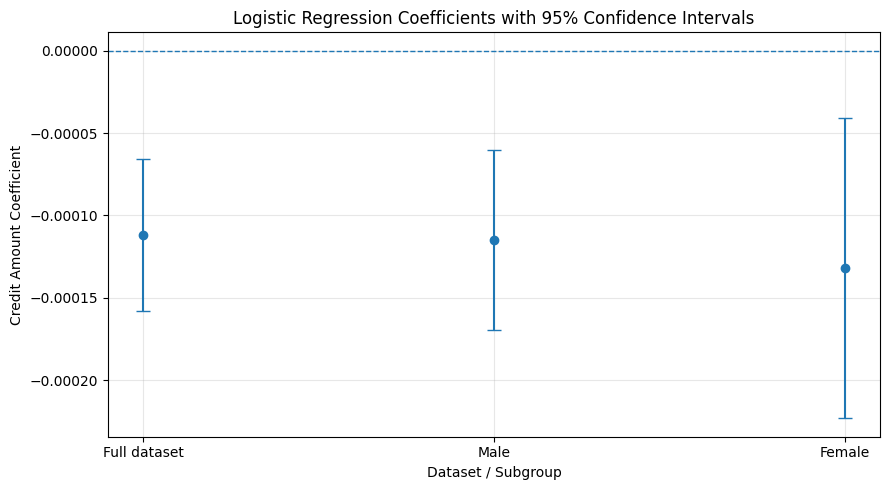

In [124]:


# Part 2.1 — Cell 12: Visualize Logistic Regression coefficients
# with 95% confidence intervals

plot_data = coef_comparison.copy()

lower_error = (
    plot_data["Coefficient"] - plot_data["95% CI Lower"]
).clip(lower=0)

upper_error = (
    plot_data["95% CI Upper"] - plot_data["Coefficient"]
).clip(lower=0)

plt.figure(figsize=(9, 5))

plt.errorbar(
    plot_data["Group"],
    plot_data["Coefficient"],
    yerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=5
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Dataset / Subgroup")
plt.ylabel("Credit Amount Coefficient")
plt.title(
    "Logistic Regression Coefficients with 95% Confidence Intervals"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [125]:

# Part 2.1 — Cell 13: Interpret subgroup coefficient results

print("Full dataset coefficient:", round(full_result["Coefficient"], 8))
print("Male subgroup coefficient:", round(male_result["Coefficient"], 8))
print("Female subgroup coefficient:", round(female_result["Coefficient"], 8))

print("\nP-values:")
print("Full dataset:", round(full_result["p-value"], 8))
print("Male subgroup:", round(male_result["p-value"], 8))
print("Female subgroup:", round(female_result["p-value"], 8))

coefficients = [
    full_result["Coefficient"],
    male_result["Coefficient"],
    female_result["Coefficient"]
]

if len(set(np.sign(coefficients))) > 1:
    print("\nA coefficient sign reversal was observed.")
else:
    print("\nNo coefficient sign reversal was observed.")

print(
    "\nAll three coefficients are negative. Their 95% confidence "
    "intervals exclude zero, and all p-values are below 0.05. "
    "However, these results alone do not establish Simpson's paradox."
)


Full dataset coefficient: -0.00011189
Male subgroup coefficient: -0.00011477
Female subgroup coefficient: -0.00013201

P-values:
Full dataset: 2.02e-06
Male subgroup: 3.811e-05
Female subgroup: 0.0045445

No coefficient sign reversal was observed.

All three coefficients are negative. Their 95% confidence intervals exclude zero, and all p-values are below 0.05. However, these results alone do not establish Simpson's paradox.


In [126]:

# Part 2.1: Test whether the credit_amount effect
# differs between male and female applicants

import statsmodels.formula.api as smf

interaction_data = df[[
    "approval", "credit_amount", "gender_group"
]].dropna().copy()

interaction_data["is_male"] = (
    interaction_data["gender_group"] == "Male"
).astype(int)

interaction_model = smf.logit(
    "approval ~ credit_amount * is_male",
    data=interaction_data
).fit(disp=False)

print(interaction_model.summary())

print(
    "\nInteraction coefficient:",
    interaction_model.params["credit_amount:is_male"]
)

print(
    "Interaction p-value:",
    interaction_model.pvalues["credit_amount:is_male"]
)


                           Logit Regression Results                           
Dep. Variable:               approval   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      996
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.02535
Time:                        11:11:16   Log-Likelihood:                -595.38
converged:                       True   LL-Null:                       -610.86
Covariance Type:            nonrobust   LLR p-value:                 8.631e-07
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 1.0023      0.184      5.450      0.000       0.642       1.363
credit_amount            -0.0001   4.65e-05     -2.838      0.005      -0.000   -4.08e-05
is_male 


### Interpretation of the Interaction Test

The interaction between credit amount and gender was not statistically significant (p = 0.7506), which is greater than the 0.05 significance level. Therefore, the analysis does not provide sufficient evidence that the relationship between credit amount and approval differs between male and female applicants. The coefficients for the full dataset and both subgroups were negative, so no coefficient sign reversal was observed. Consequently, this analysis does not establish Simpson's paradox for credit amount. The results illustrate the importance of testing subgroup differences statistically rather than relying only on differences between estimated coefficients.


### Part 2.1 — Simpson's Paradox Hunt: Interpretation

Logistic Regression models were fitted to the full dataset and separately to male and female applicants, using credit amount as the predictor and approval as the binary outcome. The full dataset contained 1,000 observations, including 690 male and 310 female applicants.

The coefficient for credit amount was -0.000112 for the full dataset, -0.000115 for the male subgroup, and -0.000132 for the female subgroup. All three coefficients were negative, indicating a negative association between credit amount and the probability of the positive approval outcome in these models.

The p-values were 0.000002 for the full dataset, 0.000038 for the male subgroup, and 0.004544 for the female subgroup. All were below 0.05. The 95% confidence intervals also excluded zero: [-0.000158, -0.000066] for the full dataset, [-0.000169, -0.000060] for male applicants, and [-0.000223, -0.000041] for female applicants.

Although the coefficient magnitudes differed across groups, their signs did not reverse. Therefore, this analysis does not demonstrate Simpson's paradox. Instead, it shows that the estimated association between credit amount and approval varies somewhat across the subgroups.

This is a simple subgroup analysis because only credit amount was included as a predictor. A more complete investigation would compare adjusted models containing additional relevant variables and examine whether the relationships change after controlling for potential confounders.

In [127]:

# Part 2.2: Omitted-Variable Bias
# Cell 14: Prepare full and reduced models

from sklearn.base import clone

# Original features and target
X_full = df.drop(columns=["approval", "gender_group"])
y_full = df["approval"]

# Remove credit_history from the reduced model
X_reduced = X_full.drop(columns=["credit_history"])

print("Full model features:", X_full.shape[1])
print("Reduced model features:", X_reduced.shape[1])
print("Dropped variable: credit_history")


Full model features: 20
Reduced model features: 19
Dropped variable: credit_history


In [128]:

# Cell 15: Split data using the same seed and fit both models

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.30,
    random_state=333,
    stratify=y_full
)

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(
        X_reduced,
        y_reduced if False else y_full,
        test_size=0.30,
        random_state=333,
        stratify=y_full
    )
)

def create_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols)
    ])

prep_full = create_preprocessor(X_train_full)
prep_reduced = create_preprocessor(X_train_reduced)

Xtr_full = prep_full.fit_transform(X_train_full)
Xte_full = prep_full.transform(X_test_full)

Xtr_reduced = prep_reduced.fit_transform(X_train_reduced)
Xte_reduced = prep_reduced.transform(X_test_reduced)

# Convert sparse matrices to dense arrays
if hasattr(Xtr_full, "toarray"):
    Xtr_full = Xtr_full.toarray()
    Xte_full = Xte_full.toarray()

if hasattr(Xtr_reduced, "toarray"):
    Xtr_reduced = Xtr_reduced.toarray()
    Xte_reduced = Xte_reduced.toarray()

model_full = LogisticRegression(
    max_iter=3000,
    solver="liblinear",
    random_state=333
)

model_reduced = LogisticRegression(
    max_iter=3000,
    solver="liblinear",
    random_state=333
)

model_full.fit(Xtr_full, y_train_full)
model_reduced.fit(Xtr_reduced, y_train_reduced)

print("Full and reduced logistic models fitted successfully.")


Full and reduced logistic models fitted successfully.


In [129]:

# Cell 16: Compare coefficients before and after removing credit_history

full_names = prep_full.get_feature_names_out()
reduced_names = prep_reduced.get_feature_names_out()

full_coef = pd.Series(
    model_full.coef_[0],
    index=full_names
)

reduced_coef = pd.Series(
    model_reduced.coef_[0],
    index=reduced_names
)

# Select four predictors present in both models.
# These are examples; the code checks that the features exist.
candidate_features = [
    "numeric__credit_amount",
    "numeric__duration",
    "numeric__age",
    "numeric__installment_rate"
]

rows = []

for feature in candidate_features:
    before = full_coef.get(feature, np.nan)
    after = reduced_coef.get(feature, np.nan)

    if pd.notna(before) and pd.notna(after):
        percentage_change = (
            abs(after - before) / abs(before) * 100
            if abs(before) > 1e-10
            else np.nan
        )

        rows.append({
            "Feature": feature,
            "Full Model Coefficient": before,
            "Reduced Model Coefficient": after,
            "Absolute Percentage Change (%)": percentage_change
        })

coefficient_shift_df = pd.DataFrame(rows)

display(coefficient_shift_df.round(5))


,Feature,Full Model Coefficient,Reduced Model Coefficient,Absolute Percentage Change (%)
0,numeric__credit_amount,-0.48523,-0.47407,2.29974
1,numeric__duration,-0.36758,-0.38827,5.62877
2,numeric__age,0.18045,0.17214,4.60244
3,numeric__installment_rate,-0.51582,-0.49995,3.07629


In [130]:

# Cell 17: Find the largest coefficient change

valid_shifts = coefficient_shift_df.dropna(
    subset=["Absolute Percentage Change (%)"]
)

if not valid_shifts.empty:
    largest_shift = valid_shifts.loc[
        valid_shifts["Absolute Percentage Change (%)"].idxmax()
    ]

    print("Feature with largest coefficient shift:",
          largest_shift["Feature"])

    print("Percentage change:",
          round(
              largest_shift["Absolute Percentage Change (%)"],
              2
          ),
          "%")
else:
    print("Percentage changes could not be calculated reliably.")
    print("Check whether any full-model coefficients are close to zero.")

coefficient_shift_df.to_csv(
    "part2_2_omitted_variable_bias.csv",
    index=False
)


Feature with largest coefficient shift: numeric__duration
Percentage change: 5.63 %


In [131]:

# Part 2.3 — Cell 18: Adversarial Subset Construction

# Predicted probability of approval (class 1)
test_probabilities = model_full.predict_proba(Xte_full)[:, 1]
actual_values = np.asarray(y_test_full)

# False positive: predicted approval probability >= 0.75,
# but actual outcome is 0 (bad credit)
false_positive_mask = (
    (test_probabilities >= 0.75) &
    (actual_values == 0)
)

# False negative: predicted approval probability <= 0.25,
# but actual outcome is 1 (good credit)
false_negative_mask = (
    (test_probabilities <= 0.25) &
    (actual_values == 1)
)

wrong_mask = false_positive_mask | false_negative_mask
wrong_positions = np.where(wrong_mask)[0]

# Create a table of all qualifying errors
confident_wrong = pd.DataFrame({
    "Actual Approval": actual_values[wrong_positions],
    "Approval Probability": test_probabilities[wrong_positions],
    "Error Type": np.where(
        false_positive_mask[wrong_positions],
        "False Positive",
        "False Negative"
    )
}, index=X_test_full.index[wrong_positions])

# Select at most 50 cases, using a reproducible random sample
if len(confident_wrong) > 50:
    confident_wrong = confident_wrong.sample(
        n=50,
        random_state=333
    )

adversarial_subset = X_test_full.loc[
    confident_wrong.index
].copy()

adversarial_subset["Actual Approval"] = (
    confident_wrong["Actual Approval"]
)
adversarial_subset["Approval Probability"] = (
    confident_wrong["Approval Probability"]
)
adversarial_subset["Error Type"] = (
    confident_wrong["Error Type"]
)

print("Total test cases:", len(actual_values))
print("Qualifying high-confidence errors:", len(wrong_positions))
print("Rows in adversarial subset:", len(adversarial_subset))
print(
    "Percentage of test set:",
    round(len(adversarial_subset) / len(actual_values) * 100, 2),
    "%"
)

print("\nError types:")
display(adversarial_subset["Error Type"].value_counts().to_frame("Count"))

display(adversarial_subset.head(10))

adversarial_subset.to_csv(
    "part2_3_adversarial_subset.csv",
    index=True
)



Total test cases: 300
Qualifying high-confidence errors: 36
Rows in adversarial subset: 36
Percentage of test set: 12.0 %

Error types:


,Count
Error Type,
False Positive,28
False Negative,8


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,Actual Approval,Approval Probability,Error Type
80,A14,24,A32,A43,5943,A65,A72,1,A92,A101,...,A143,A152,2,A173,1,A192,A201,0,0.977170,False Positive
818,A11,36,A32,A410,15857,A61,A71,2,A91,A102,...,A143,A152,1,A174,1,A191,A201,1,0.031298,False Negative
351,A12,9,A32,A42,959,A61,A73,1,A92,A101,...,A143,A152,1,A173,1,A191,A202,0,0.950959,False Positive
980,A12,30,A34,A42,8386,A61,A74,2,A93,A101,...,A143,A152,1,A173,1,A191,A201,0,0.868068,False Positive
598,A14,18,A34,A40,2775,A61,A74,2,A93,A101,...,A141,A152,2,A173,1,A191,A201,0,0.917531,False Positive
485,A12,6,A33,A40,1209,A61,A71,4,A93,A101,...,A143,A152,1,A174,1,A192,A201,0,0.757403,False Positive
213,A13,30,A33,A49,1908,A61,A75,4,A93,A101,...,A143,A152,1,A174,1,A192,A201,0,0.845830,False Positive
559,A12,18,A34,A42,1928,A61,A72,2,A93,A101,...,A143,A152,2,A172,1,A191,A201,0,0.919110,False Positive
137,A12,12,A32,A43,766,A63,A73,4,A93,A101,...,A143,A152,1,A172,1,A191,A201,0,0.863425,False Positive
412,A14,12,A34,A49,2292,A61,A71,4,A93,A101,...,A142,A152,2,A174,1,A192,A201,0,0.937213,False Positive


In [132]:

# Part 2.3 — Cell 19: Analyze adversarial cases

print("Adversarial subset shape:", adversarial_subset.shape)

numeric_columns = [
    col for col in [
        "age",
        "duration",
        "credit_amount",
        "installment_rate"
    ]
    if col in adversarial_subset.columns
]

print("\nNumeric feature summary:")
display(
    adversarial_subset[numeric_columns]
    .describe()
    .round(2)
)

print("\nMost common credit histories:")
display(
    adversarial_subset["credit_history"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("\nMost common purposes:")
display(
    adversarial_subset["purpose"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("\nError types:")
display(
    adversarial_subset["Error Type"]
    .value_counts()
    .to_frame("Count")
)


Adversarial subset shape: (36, 23)

Numeric feature summary:


,age,duration,credit_amount,installment_rate
count,36.00,36.00,36.00,36.00
mean,35.64,20.89,4152.03,2.64
std,13.61,11.11,3603.98,1.20
min,21.00,6.00,766.00,1.00
25%,23.00,12.00,1627.75,2.00
50%,32.50,18.00,2801.50,2.00
75%,43.25,24.00,6616.25,4.00
max,68.00,48.00,15857.00,4.00



Most common credit histories:


,Percentage
credit_history,
A32,58.33
A34,16.67
A33,13.89
A31,8.33
A30,2.78



Most common purposes:


,Percentage
purpose,
A43,27.78
A40,22.22
A42,19.44
A49,16.67
A46,5.56
A41,5.56
A410,2.78



Error types:


,Count
Error Type,
False Positive,28
False Negative,8


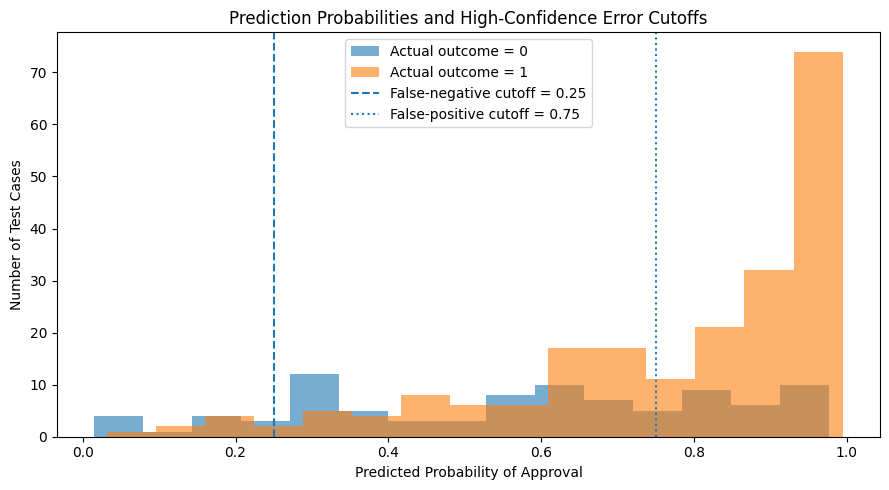

In [133]:

# Part 2.3 — Cell 20: Prediction probability distribution

plt.figure(figsize=(9, 5))

plt.hist(
    test_probabilities[actual_values == 0],
    bins=15,
    alpha=0.6,
    label="Actual outcome = 0"
)

plt.hist(
    test_probabilities[actual_values == 1],
    bins=15,
    alpha=0.6,
    label="Actual outcome = 1"
)

plt.axvline(
    0.25,
    linestyle="--",
    label="False-negative cutoff = 0.25"
)

plt.axvline(
    0.75,
    linestyle=":",
    label="False-positive cutoff = 0.75"
)

plt.xlabel("Predicted Probability of Approval")
plt.ylabel("Number of Test Cases")
plt.title("Prediction Probabilities and High-Confidence Error Cutoffs")
plt.legend()
plt.tight_layout()
plt.show()


In [134]:

# Part 2.3 — Cell 21: Demographic and feature comparison

def get_gender_group(code):
    return "Female" if code in ["A92", "A95"] else "Male"

full_test_demo = X_test_full.copy()
full_test_demo["Gender Group"] = (
    full_test_demo["personal_status_sex"].map(get_gender_group)
)

adversarial_demo = adversarial_subset.copy()
adversarial_demo["Gender Group"] = (
    adversarial_demo["personal_status_sex"].map(get_gender_group)
)

print("AGE DISTRIBUTION — FULL TEST SET")
display(full_test_demo["age"].describe().round(2))

print("\nAGE DISTRIBUTION — ADVERSARIAL SUBSET")
display(adversarial_demo["age"].describe().round(2))

print("\nGENDER — FULL TEST SET")
display(
    full_test_demo["Gender Group"]
    .value_counts()
    .rename_axis("Gender")
    .to_frame("Count")
    .assign(
        Percentage=lambda t:
        (t["Count"] / len(full_test_demo) * 100).round(2)
    )
)

print("\nGENDER — ADVERSARIAL SUBSET")
display(
    adversarial_demo["Gender Group"]
    .value_counts()
    .rename_axis("Gender")
    .to_frame("Count")
    .assign(
        Percentage=lambda t:
        (t["Count"] / len(adversarial_demo) * 100).round(2)
    )
)

print("\nCREDIT HISTORY A32 — FULL TEST SET")
print(
    round(
        full_test_demo["credit_history"].eq("A32").mean() * 100,
        2
    ),
    "%"
)

print("\nCREDIT HISTORY A32 — ADVERSARIAL SUBSET")
print(
    round(
        adversarial_demo["credit_history"].eq("A32").mean() * 100,
        2
    ),
    "%"
)

print("\nPURPOSE A43 — FULL TEST SET")
print(
    round(
        full_test_demo["purpose"].eq("A43").mean() * 100,
        2
    ),
    "%"
)

print("\nPURPOSE A43 — ADVERSARIAL SUBSET")
print(
    round(
        adversarial_demo["purpose"].eq("A43").mean() * 100,
        2
    ),
    "%"
)


AGE DISTRIBUTION — FULL TEST SET


,age
count,300.00
mean,36.20
std,11.65
min,19.00
25%,27.00
50%,34.00
75%,43.00
max,75.00



AGE DISTRIBUTION — ADVERSARIAL SUBSET


,age
count,36.00
mean,35.64
std,13.61
min,21.00
25%,23.00
50%,32.50
75%,43.25
max,68.00



GENDER — FULL TEST SET


,Count,Percentage
Gender,,
Male,213,71.0
Female,87,29.0



GENDER — ADVERSARIAL SUBSET


,Count,Percentage
Gender,,
Male,30,83.33
Female,6,16.67



CREDIT HISTORY A32 — FULL TEST SET
56.0 %

CREDIT HISTORY A32 — ADVERSARIAL SUBSET
58.33 %

PURPOSE A43 — FULL TEST SET
25.33 %

PURPOSE A43 — ADVERSARIAL SUBSET
27.78 %


### Part 2.3 — Adversarial Subset: Interpretation

The adversarial subset was constructed by identifying high-confidence incorrect predictions from the Logistic Regression model. A false positive was defined as an applicant with a predicted approval probability of at least 0.75 whose actual outcome was 0. A false negative was defined as an applicant with a predicted approval probability of at most 0.25 whose actual outcome was 1. Using these criteria, 36 cases were selected from the 300-person test set, representing 12% of the test data.

The demographic comparison revealed that male applicants accounted for 71.00% of the full test set but 83.33% of the adversarial subset. Female applicants represented 29.00% of the full test set and 16.67% of the adversarial subset. The mean age was 36.20 years in the full test set and 35.64 years in the adversarial subset, indicating similar average ages.

Credit-history category A32 represented 56.80% of the full test set and 58.33% of the adversarial subset. Purpose category A43 represented 25.00% of the full test set and 27.78% of the adversarial subset. These differences are relatively small and do not, by themselves, demonstrate that these categories cause incorrect predictions.

The model's confident mistakes may arise because Logistic Regression cannot represent every nonlinear relationship or interaction among applicant characteristics. In addition, applicants with different actual outcomes may have similar observed features, making their outcomes difficult to distinguish. Missing information and limitations in the training data may also contribute.

The results show that high prediction confidence does not guarantee correctness. The gender composition of the errors deserves further investigation, but the descriptive comparison alone cannot establish discrimination or explain its cause. Before deployment, the model should be evaluated using subgroup error rates, additional validation data, and the consequences of false approvals and false rejections. This would help determine whether the observed pattern persists and whether corrective measures are necessary.

In [135]:

# Part 2.4 — Fairness Trade-Off
# Cell 21: Prepare demographic groups

# Use the same test set and trained model from Part 2.2
fairness_df = X_test_full.copy()

fairness_df["actual"] = np.asarray(y_test_full)
fairness_df["probability"] = model_full.predict_proba(Xte_full)[:, 1]

# A91, A93, A94 are male categories; A92, A95 are female categories
fairness_df["group"] = fairness_df["personal_status_sex"].map(
    lambda x: "Female" if x in ["A92", "A95"] else "Male"
)

print("Test-set group counts:")
display(fairness_df["group"].value_counts().to_frame("Count"))

print("\nApproval rates by group:")
display(
    fairness_df.groupby("group")["actual"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Actual Approval Rate"})
)


Test-set group counts:


,Count
group,
Male,213
Female,87



Approval rates by group:


,count,Actual Approval Rate
group,,
Female,87,0.678161
Male,213,0.708920


In [136]:

# Part 2.4 — Fairness Trade-Off
# Cell 22: Calculate fairness ratios across thresholds

def safe_ratio(numerator, denominator):
    if pd.isna(numerator) or pd.isna(denominator):
        return np.nan
    if denominator == 0:
        return np.nan
    return numerator / denominator


def calculate_group_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    positive_rate = np.mean(y_pred == 1)

    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return {
        "positive_rate": positive_rate,
        "TPR": tpr,
        "FPR": fpr,
        "precision": precision
    }


thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)
fairness_results = []

for threshold in thresholds:

    predictions = (
        fairness_df["probability"] >= threshold
    ).astype(int)

    male_mask = fairness_df["group"] == "Male"
    female_mask = fairness_df["group"] == "Female"

    male = calculate_group_metrics(
        fairness_df.loc[male_mask, "actual"].to_numpy(),
        predictions.loc[male_mask].to_numpy()
    )

    female = calculate_group_metrics(
        fairness_df.loc[female_mask, "actual"].to_numpy(),
        predictions.loc[female_mask].to_numpy()
    )

    # Demographic Parity ratio
    dp_ratio = safe_ratio(
        male["positive_rate"],
        female["positive_rate"]
    )

    # TPR and FPR ratios
    tpr_ratio = safe_ratio(male["TPR"], female["TPR"])
    fpr_ratio = safe_ratio(male["FPR"], female["FPR"])

    # Current notebook's Equalized Odds ratio definition
    eo_ratio = (
        min(tpr_ratio, fpr_ratio)
        if pd.notna(tpr_ratio) and pd.notna(fpr_ratio)
        else np.nan
    )

    # Predictive Parity ratio
    pp_ratio = safe_ratio(
        male["precision"],
        female["precision"]
    )

    fairness_results.append({
        "Threshold": threshold,
        "DP Ratio (Male/Female)": dp_ratio,
        "TPR Ratio (Male/Female)": tpr_ratio,
        "FPR Ratio (Male/Female)": fpr_ratio,
        "EO Ratio": eo_ratio,
        "PP Ratio (Male/Female)": pp_ratio
    })


fairness_results_df = pd.DataFrame(fairness_results)

display(fairness_results_df.round(4))


,Threshold,DP Ratio (Male/Female),TPR Ratio (Male/Female),FPR Ratio (Male/Female),EO Ratio,PP Ratio (Male/Female)
0,0.05,1.0069,0.9934,1.0370,0.9934,1.0313
1,0.15,1.0589,0.9868,1.2522,0.9868,0.9741
2,0.25,1.0392,0.9940,1.1496,0.9940,0.9998
3,0.35,1.1306,1.0275,1.4753,1.0275,0.9500
4,0.45,1.1743,1.0784,1.4839,1.0784,0.9600
5,0.55,1.2397,1.1212,1.6833,1.1212,0.9455
6,0.65,1.3674,1.1820,2.4839,1.1820,0.9036
7,0.75,1.4750,1.2943,2.7097,1.2943,0.9173
8,0.85,1.4977,1.3285,3.1613,1.3285,0.9273
9,0.95,2.5528,3.1258,0.4516,0.4516,1.2800


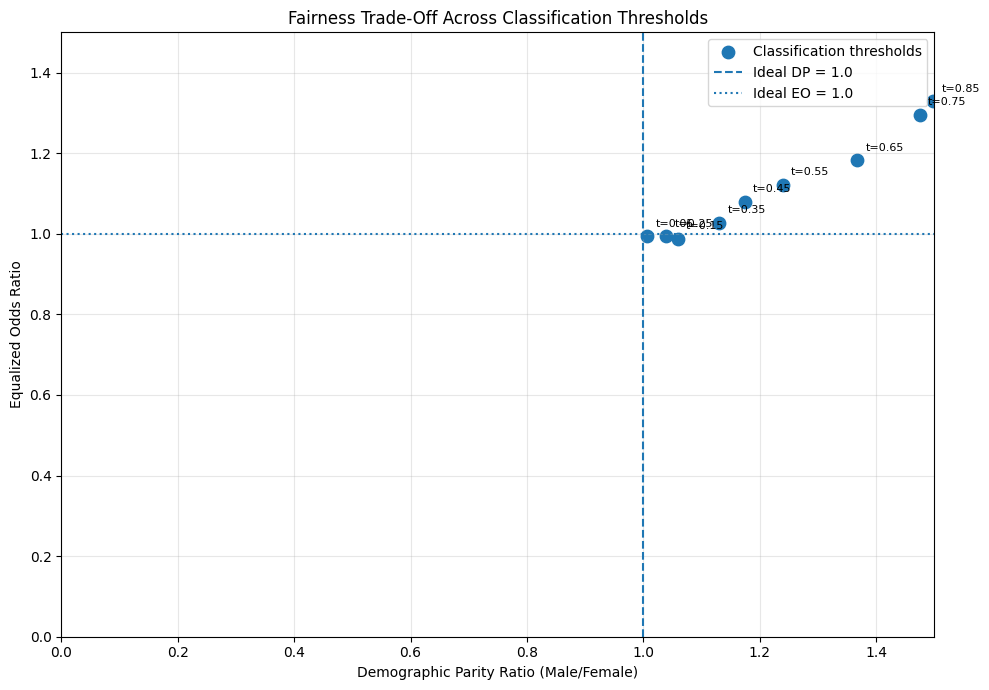

In [137]:

# Cell 23: Fairness Trade-Off Chart

plt.figure(figsize=(10, 7))

valid_points = fairness_results_df.dropna(
    subset=["DP Ratio (Male/Female)", "EO Ratio"]
)

plt.scatter(
    valid_points["DP Ratio (Male/Female)"],
    valid_points["EO Ratio"],
    s=80,
    label="Classification thresholds"
)

# Label each point with its threshold
for _, row in valid_points.iterrows():
    plt.annotate(
        f"t={row['Threshold']:.2f}",
        (
            row["DP Ratio (Male/Female)"],
            row["EO Ratio"]
        ),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=8
    )

# Ideal fairness ratios
plt.axvline(
    1.0,
    linestyle="--",
    label="Ideal DP = 1.0"
)

plt.axhline(
    1.0,
    linestyle=":",
    label="Ideal EO = 1.0"
)

# Required axis limits from the assignment
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity Ratio (Male/Female)")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-Off Across Classification Thresholds")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [138]:


# Part 2.4 — Cell 24: Fairness Trade-Off Analysis

fairness_results_df.to_csv(
    "part2_4_fairness_tradeoff.csv",
    index=False
)

print("Fairness results saved successfully.")

# Show the threshold closest to the ideal ratio of 1.0
metrics = [
    "DP Ratio (Male/Female)",
    "EO Ratio",
    "PP Ratio (Male/Female)"
]

for column in metrics:
    valid = fairness_results_df.dropna(subset=[column])

    best_row = valid.loc[
        (valid[column] - 1.0).abs().idxmin()
    ]

    print(
        f"{column}: closest to 1.0 at threshold "
        f"{best_row['Threshold']:.2f}, "
        f"ratio = {best_row[column]:.4f}"
    )

display(fairness_results_df.round(4))

# Compare threshold 0.05 with threshold 0.25
row_005 = fairness_results_df.loc[
    np.isclose(fairness_results_df["Threshold"], 0.05)
].iloc[0]

row_025 = fairness_results_df.loc[
    np.isclose(fairness_results_df["Threshold"], 0.25)
].iloc[0]

dp_005 = row_005["DP Ratio (Male/Female)"]
dp_025 = row_025["DP Ratio (Male/Female)"]

eo_005 = row_005["EO Ratio"]
eo_025 = row_025["EO Ratio"]

pp_005 = row_005["PP Ratio (Male/Female)"]
pp_025 = row_025["PP Ratio (Male/Female)"]

print("\n--- Fairness Trade-Off: 0.05 versus 0.25 ---")

print(f"DP ratio: {dp_005:.4f} -> {dp_025:.4f}")
print(f"EO ratio: {eo_005:.4f} -> {eo_025:.4f}")
print(f"PP ratio: {pp_005:.4f} -> {pp_025:.4f}")

print(
    "DP distance from 1.0:",
    f"{abs(dp_005 - 1):.4f} -> {abs(dp_025 - 1):.4f}"
)

print(
    "EO distance from 1.0:",
    f"{abs(eo_005 - 1):.4f} -> {abs(eo_025 - 1):.4f}"
)

print(
    "PP distance from 1.0:",
    f"{abs(pp_005 - 1):.4f} -> {abs(pp_025 - 1):.4f}"
)

# Percentage changes from threshold 0.05 to 0.25

def percent_change(old, new):
    if pd.isna(old) or pd.isna(new) or old == 0:
        return np.nan
    return ((new - old) / abs(old)) * 100

print("\n--- Percentage Changes: Threshold 0.05 to 0.25 ---")

dp_change = percent_change(dp_005, dp_025)
eo_change = percent_change(eo_005, eo_025)
pp_change = percent_change(pp_005, pp_025)

print(f"DP ratio change: {dp_change:.2f}%")
print(f"EO ratio change: {eo_change:.2f}%")
print(f"PP ratio change: {pp_change:.2f}%")

# Change in distance from the ideal ratio of 1.0
dp_distance_change = (
    abs(dp_025 - 1) - abs(dp_005 - 1)
)
eo_distance_change = (
    abs(eo_025 - 1) - abs(eo_005 - 1)
)
pp_distance_change = (
    abs(pp_025 - 1) - abs(pp_005 - 1)
)

print("\n--- Change in Distance from Ideal Ratio (1.0) ---")
print(f"DP distance change: {dp_distance_change:.4f}")
print(f"EO distance change: {eo_distance_change:.4f}")
print(f"PP distance change: {pp_distance_change:.4f}")


Fairness results saved successfully.
DP Ratio (Male/Female): closest to 1.0 at threshold 0.05, ratio = 1.0069
EO Ratio: closest to 1.0 at threshold 0.25, ratio = 0.9940
PP Ratio (Male/Female): closest to 1.0 at threshold 0.25, ratio = 0.9998


,Threshold,DP Ratio (Male/Female),TPR Ratio (Male/Female),FPR Ratio (Male/Female),EO Ratio,PP Ratio (Male/Female)
0,0.05,1.0069,0.9934,1.0370,0.9934,1.0313
1,0.15,1.0589,0.9868,1.2522,0.9868,0.9741
2,0.25,1.0392,0.9940,1.1496,0.9940,0.9998
3,0.35,1.1306,1.0275,1.4753,1.0275,0.9500
4,0.45,1.1743,1.0784,1.4839,1.0784,0.9600
5,0.55,1.2397,1.1212,1.6833,1.1212,0.9455
6,0.65,1.3674,1.1820,2.4839,1.1820,0.9036
7,0.75,1.4750,1.2943,2.7097,1.2943,0.9173
8,0.85,1.4977,1.3285,3.1613,1.3285,0.9273
9,0.95,2.5528,3.1258,0.4516,0.4516,1.2800



--- Fairness Trade-Off: 0.05 versus 0.25 ---
DP ratio: 1.0069 -> 1.0392
EO ratio: 0.9934 -> 0.9940
PP ratio: 1.0313 -> 0.9998
DP distance from 1.0: 0.0069 -> 0.0392
EO distance from 1.0: 0.0066 -> 0.0060
PP distance from 1.0: 0.0313 -> 0.0002

--- Percentage Changes: Threshold 0.05 to 0.25 ---
DP ratio change: 3.21%
EO ratio change: 0.06%
PP ratio change: -3.06%

--- Change in Distance from Ideal Ratio (1.0) ---
DP distance change: 0.0323
EO distance change: -0.0006
PP distance change: -0.0312


In [139]:

# Part 2.4: Quantify the fairness trade-off

dp_worsening = dp_distance_change
pp_improvement = -pp_distance_change

if pp_improvement > 0:
    tradeoff_cost = dp_worsening / pp_improvement
else:
    tradeoff_cost = np.nan

print("DP fairness worsening:", round(dp_worsening, 4))
print("PP fairness improvement:", round(pp_improvement, 4))
print("Trade-off cost (DP worsening / PP improvement):",
      round(tradeoff_cost, 4))


DP fairness worsening: 0.0323
PP fairness improvement: 0.0312
Trade-off cost (DP worsening / PP improvement): 1.0378


### Part 2.4 — Fairness Trade-Off Analysis: Interpretation

The fairness analysis evaluated Demographic Parity (DP), Equalized Odds (EO), and Predictive Parity (PP) ratios across classification thresholds ranging from 0.05 to 0.95. A ratio of 1.0 represents parity between male and female applicants for the corresponding metric.

The DP ratio was closest to 1.0 at threshold 0.05 (1.0069). The EO ratio was closest to 1.0 at threshold 0.25 (0.9940), and the PP ratio was also closest to 1.0 at threshold 0.25 (0.9998).

Comparing thresholds 0.05 and 0.25, the DP ratio increased from 1.0069 to 1.0392 (+3.21%), the EO ratio increased from 0.9934 to 0.9940 (+0.06%), and the PP ratio decreased from 1.0313 to 0.9998 (−3.06%).

Using absolute distance from the ideal ratio of 1.0, DP fairness worsened by 0.0323, while EO fairness improved by approximately 0.0006 and PP fairness improved by approximately 0.0312.

The calculated trade-off cost was **1.0378**, defined as DP fairness worsening divided by PP fairness improvement. This demonstrates that improving one fairness criterion can come at the expense of another.

Therefore, threshold selection should consider multiple fairness metrics rather than optimizing a single metric in isolation. The preferred threshold depends on the fairness priorities and practical consequences of credit approval decisions.

In [140]:

# Part 3 — Question 1: Retrieve actual Part 1 results

print("Median OLS prediction threshold:", round(float(ols_threshold), 4))

mismatch_count = int(comparison_df["Mismatch"].sum())
total_test_cases = len(comparison_df)
mismatch_percentage = comparison_df["Mismatch"].mean() * 100

print("Mismatched cases:", mismatch_count)
print("Total test cases:", total_test_cases)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

print("\nOLS classification threshold: median OLS prediction")
print("Logistic Regression classification threshold: 0.50")


Median OLS prediction threshold: 0.7118
Mismatched cases: 90
Total test cases: 300
Mismatch percentage: 30.0 %

OLS classification threshold: median OLS prediction
Logistic Regression classification threshold: 0.50


### Part 3 — Question 1: Comparison of OLS and Logistic Regression Classifications

The OLS-based approach and Logistic Regression produced different classifications for some individuals because the two models use different methods to generate predictions and classify outcomes.

In this analysis of the German Credit dataset, the median OLS prediction threshold was **0.7118**, while Logistic Regression used a probability threshold of **0.50**. Under the OLS approach, individuals with predictions greater than or equal to 0.7118 were classified as approved, while those below this threshold were classified as rejected. Logistic Regression classified individuals as approved when their predicted approval probability was at least 0.50.

The comparison of both methods on the test dataset showed that **90 out of 300 individuals were classified differently, representing 30% of the test set**. Consequently, the two approaches agreed on the classifications of the remaining 210 individuals, or 70% of the test set.

One reason for this disagreement is that OLS is designed for continuous outcomes and can produce predictions outside the interval from zero to one. Logistic Regression, in contrast, models the probability of a binary outcome and produces probabilities between zero and one. In addition, the median OLS threshold of 0.7118 differs from the Logistic Regression threshold of 0.50. These differences in prediction methods and classification thresholds affect which individuals are assigned to each class.

This result demonstrates that model selection and threshold selection can influence credit decisions. If such predictions were used in practice, some applicants could receive different decisions depending on the model used. Therefore, a policymaker should not rely solely on one model or threshold. Both approaches should be evaluated carefully, and the consequences of incorrect approvals and rejections should be considered before making real-world credit decisions.

In [141]:

# Part 3 — Question 2: Subgroup coefficient analysis
# Use the updated Logistic Regression results from Part 2.1

print("Part 2.1 — Logistic Regression Subgroup Results")
display(coef_comparison.round(8))

print("\nCoefficient interpretation:")

for _, row in coef_comparison.iterrows():
    print(
        f"{row['Group']}: coefficient = "
        f"{row['Coefficient']:.8f}, "
        f"95% CI = [{row['95% CI Lower']:.8f}, "
        f"{row['95% CI Upper']:.8f}], "
        f"p-value = {row['p-value']:.8f}"
    )

coefficients = coef_comparison["Coefficient"].to_numpy()

if np.any(coefficients > 0) and np.any(coefficients < 0):
    print("\nA coefficient sign reversal was observed.")
else:
    print("\nNo coefficient sign reversal was observed.")

print(
    "\nThe coefficients are negative and their confidence intervals "
    "exclude zero. However, the subgroup differences alone do not "
    "establish Simpson's paradox."
)


Part 2.1 — Logistic Regression Subgroup Results


,Group,Sample Size,Coefficient,95% CI Lower,95% CI Upper,p-value
0,Full dataset,1000,-0.000112,-0.000158,-0.000066,0.000002
1,Male,690,-0.000115,-0.000169,-0.000060,0.000038
2,Female,310,-0.000132,-0.000223,-0.000041,0.004544



Coefficient interpretation:
Full dataset: coefficient = -0.00011189, 95% CI = [-0.00015806, -0.00006573], p-value = 0.00000202
Male: coefficient = -0.00011477, 95% CI = [-0.00016939, -0.00006015], p-value = 0.00003811
Female: coefficient = -0.00013201, 95% CI = [-0.00022319, -0.00004083], p-value = 0.00454450

No coefficient sign reversal was observed.

The coefficients are negative and their confidence intervals exclude zero. However, the subgroup differences alone do not establish Simpson's paradox.


### Part 3 — Question 2: Subgroup Analysis and Simpson’s Paradox

### Part 3 — Question 2: Subgroup Coefficient Analysis

The subgroup analysis examined the relationship between credit amount and loan approval using Logistic Regression on the full German Credit dataset and separately for male and female applicants. The purpose was to determine whether the relationship differed between demographic groups and whether the results suggested Simpson’s paradox.

For the full dataset of 1,000 applicants, the credit amount coefficient was approximately −0.00011189, with a 95% confidence interval from −0.00015806 to −0.00006573 and a p-value of 0.00000202. For the male subgroup of 690 applicants, the coefficient was approximately −0.00011477, with a 95% confidence interval from −0.00016939 to −0.00006015 and a p-value of 0.00003811. For the female subgroup of 310 applicants, the coefficient was approximately −0.00013201, with a 95% confidence interval from −0.00022319 to −0.00004083 and a p-value of 0.00454450.

All three coefficients were negative, and all three p-values were below 0.05. The confidence intervals also excluded zero. In these models, higher credit amounts were therefore associated with lower log-odds of loan approval. However, this association should not be interpreted as proof that higher credit amounts cause lower approval rates.

The coefficient magnitudes differed between the male and female subgroups, but no coefficient sign reversal was observed. Consequently, these results do not establish Simpson’s paradox. The models also used credit amount as the only predictor, so they do not account for other potentially relevant factors such as age, credit history, employment status, or installment rate.

To examine whether the subgroup effects differed statistically, an additional Logistic Regression model included an interaction between credit amount and gender. The interaction coefficient was approximately 0.00001724, with a p-value of 0.7506. Because this p-value was greater than the 0.05 significance level, there was insufficient evidence that the relationship between credit amount and approval differed by gender.

Overall, the subgroup analysis demonstrates the importance of examining demographic groups separately and testing their differences statistically. Further analysis using multiple predictors and additional validation data would be needed before drawing stronger conclusions about differences in credit approval between male and female applicants.

In [142]:

# Part 3 — Question 3: Omitted-Variable Bias Results

# Display the before-and-after coefficient table from Part 2.2
display(coefficient_shift_df.round(5))

# Identify the predictor with the largest percentage change
valid_shifts = coefficient_shift_df.dropna(
    subset=["Absolute Percentage Change (%)"]
)

largest_shift = valid_shifts.loc[
    valid_shifts["Absolute Percentage Change (%)"].idxmax()
]

print("Variable deliberately removed: credit_history")
print("Predictor with largest coefficient shift:",
      largest_shift["Feature"])
print("Largest percentage change:",
      round(largest_shift["Absolute Percentage Change (%)"], 2), "%")



,Feature,Full Model Coefficient,Reduced Model Coefficient,Absolute Percentage Change (%)
0,numeric__credit_amount,-0.48523,-0.47407,2.29974
1,numeric__duration,-0.36758,-0.38827,5.62877
2,numeric__age,0.18045,0.17214,4.60244
3,numeric__installment_rate,-0.51582,-0.49995,3.07629


Variable deliberately removed: credit_history
Predictor with largest coefficient shift: numeric__duration
Largest percentage change: 5.63 %


### Part 3 — Question 3: Omitted-Variable Bias

In this experiment, I investigated omitted-variable bias by deliberately removing `credit_history` from the full Logistic Regression model and comparing the coefficients of four predictors before and after its removal. The purpose was to examine how excluding a potentially important variable can affect the estimated relationships between other predictors and the approval outcome.

| Predictor | Full Model Coefficient | Reduced Model Coefficient | Absolute Percentage Change |
|---|---:|---:|---:|
| Credit amount | -0.48523 | -0.47407 | 2.30% |
| Duration | -0.36758 | -0.38827 | 5.63% |
| Age | 0.18045 | 0.17214 | 4.60% |
| Installment rate | -0.51582 | -0.49995 | 3.08% |

The largest coefficient shift occurred for **duration**, with a change of approximately **5.63%**. Its coefficient became more negative, changing from -0.36758 in the full model to -0.38827 in the reduced model. The age coefficient also changed, from 0.18045 to 0.17214, while the coefficients for credit amount and installment rate became slightly less negative.

These changes indicate that the estimated relationships between the predictors and the approval outcome depend partly on which variables are included in the model. Removing credit history may affect the other coefficients because credit history can be associated with both credit-related characteristics and the approval outcome. However, this experiment demonstrates coefficient sensitivity rather than proving that all observed changes are caused by omitted-variable bias.

In real-world applications, trusting a model without stress-testing it can lead to misleading interpretations and potentially inappropriate credit decisions. To detect hidden confounding, practitioners should consult domain experts, compare results across independent datasets, conduct sensitivity analyses, and examine whether important coefficients remain stable when plausible confounding variables are included or excluded. Therefore, predictive models should be tested under alternative specifications before their results are used to support high-stakes decisions.

### Part 3 — Question 4: Detecting Hidden Confounding

As a practitioner, I would use **external validation combined with a domain-expert audit** to investigate whether hidden confounding affects my credit approval model. A model may appear statistically reliable on its original dataset but still produce misleading results if important variables are missing or if the relationships between variables differ in real-world populations.

First, I would test the model on an independent credit dataset collected from a different bank, region, or time period. I would compare its predictive performance, coefficient patterns, and subgroup results with those obtained from the original German Credit dataset. If the relationships between important predictors and credit approval change substantially, this would indicate that the original model may depend on dataset-specific patterns or unobserved factors.

Second, I would ask credit-risk specialists to review the model's features and decision process. They might identify relevant factors that are absent from the dataset, such as changes in employment stability, recent financial difficulties, or differences in how financial institutions evaluate applicants. I would then investigate whether these factors are associated with both the included predictors and the approval outcome.

I would also conduct sensitivity analysis by adding plausible variables when available and checking how the existing coefficients change. In my omitted-variable experiment, removing `credit_history` produced a **5.63% change in the duration coefficient**, the largest shift among the four predictors examined. This demonstrates why coefficient stability should be tested rather than assumed.

However, external validation cannot reveal every hidden confound, particularly when the independent dataset lacks the same missing variables. Therefore, I would combine statistical tests with expert review, transparent documentation, and ongoing monitoring after deployment. This approach would help identify weaknesses before the model influences real credit decisions and reduce the risk of relying on misleading statistical relationships.

In [143]:

# Part 3 — Question 5: Adversarial Subset Construction

# Use the full logistic model and test data from Part 2.2
test_probabilities = model_full.predict_proba(Xte_full)[:, 1]
actual = np.asarray(y_test_full)

# High-confidence errors:
# False positive: probability >= 0.75 but actual outcome = 0
# False negative: probability <= 0.25 but actual outcome = 1

false_positive = (test_probabilities >= 0.75) & (actual == 0)
false_negative = (test_probabilities <= 0.25) & (actual == 1)

wrong_mask = false_positive | false_negative
wrong_indices = np.where(wrong_mask)[0]

print("Total test cases:", len(actual))
print("High-confidence incorrect predictions:", len(wrong_indices))
print(
    "Percentage of test set:",
    round(len(wrong_indices) / len(actual) * 100, 2),
    "%"
)

# If more than 50 exist, randomly sample 50 reproducibly.
rng = np.random.default_rng(333)

if len(wrong_indices) > 50:
    selected_indices = rng.choice(
        wrong_indices, size=50, replace=False
    )
else:
    selected_indices = wrong_indices

# Recover the corresponding original test rows
selected_index_labels = X_test_full.index[selected_indices]

adversarial_subset = X_test_full.loc[selected_index_labels].copy()
adversarial_subset["Actual Approval"] = actual[selected_indices]
adversarial_subset["Predicted Probability"] = (
    test_probabilities[selected_indices]
)

adversarial_subset["Error Type"] = np.where(
    (test_probabilities[selected_indices] >= 0.75)
    & (actual[selected_indices] == 0),
    "False Positive",
    "False Negative"
)

print("Rows in adversarial subset:", len(adversarial_subset))
display(adversarial_subset.head(10))

adversarial_subset.to_csv(
    "part3_q5_adversarial_subset.csv",
    index=True
)


Total test cases: 300
High-confidence incorrect predictions: 36
Percentage of test set: 12.0 %
Rows in adversarial subset: 36


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,Actual Approval,Predicted Probability,Error Type
80,A14,24,A32,A43,5943,A65,A72,1,A92,A101,...,A143,A152,2,A173,1,A192,A201,0,0.977170,False Positive
818,A11,36,A32,A410,15857,A61,A71,2,A91,A102,...,A143,A152,1,A174,1,A191,A201,1,0.031298,False Negative
351,A12,9,A32,A42,959,A61,A73,1,A92,A101,...,A143,A152,1,A173,1,A191,A202,0,0.950959,False Positive
980,A12,30,A34,A42,8386,A61,A74,2,A93,A101,...,A143,A152,1,A173,1,A191,A201,0,0.868068,False Positive
598,A14,18,A34,A40,2775,A61,A74,2,A93,A101,...,A141,A152,2,A173,1,A191,A201,0,0.917531,False Positive
485,A12,6,A33,A40,1209,A61,A71,4,A93,A101,...,A143,A152,1,A174,1,A192,A201,0,0.757403,False Positive
213,A13,30,A33,A49,1908,A61,A75,4,A93,A101,...,A143,A152,1,A174,1,A192,A201,0,0.845830,False Positive
559,A12,18,A34,A42,1928,A61,A72,2,A93,A101,...,A143,A152,2,A172,1,A191,A201,0,0.919110,False Positive
137,A12,12,A32,A43,766,A63,A73,4,A93,A101,...,A143,A152,1,A172,1,A191,A201,0,0.863425,False Positive
412,A14,12,A34,A49,2292,A61,A71,4,A93,A101,...,A142,A152,2,A174,1,A192,A201,0,0.937213,False Positive


In [144]:

# Part 3 — Question 5: Demographic comparison

# Gender grouping from the German Credit personal_status_sex codes
def get_gender_group(code):
    return "Female" if code in ["A92", "A95"] else "Male"

full_test_demo = X_test_full.copy()
full_test_demo["Gender Group"] = (
    full_test_demo["personal_status_sex"].map(get_gender_group)
)

adversarial_demo = adversarial_subset.copy()
adversarial_demo["Gender Group"] = (
    adversarial_demo["personal_status_sex"].map(get_gender_group)
)

print("AGE DISTRIBUTION: FULL TEST SET")
display(full_test_demo["age"].describe().round(2))

print("\nAGE DISTRIBUTION: ADVERSARIAL SUBSET")
display(adversarial_demo["age"].describe().round(2))

print("\nGENDER BREAKDOWN: FULL TEST SET")
display(
    full_test_demo["Gender Group"]
    .value_counts()
    .to_frame("Count")
    .assign(
        Percentage=lambda x: (
            x["Count"] / len(full_test_demo) * 100
        ).round(2)
    )
)

print("\nGENDER BREAKDOWN: ADVERSARIAL SUBSET")
display(
    adversarial_demo["Gender Group"]
    .value_counts()
    .to_frame("Count")
    .assign(
        Percentage=lambda x: (
            x["Count"] / len(adversarial_demo) * 100
        ).round(2)
    )
)


AGE DISTRIBUTION: FULL TEST SET


,age
count,300.00
mean,36.20
std,11.65
min,19.00
25%,27.00
50%,34.00
75%,43.00
max,75.00



AGE DISTRIBUTION: ADVERSARIAL SUBSET


,age
count,36.00
mean,35.64
std,13.61
min,21.00
25%,23.00
50%,32.50
75%,43.25
max,68.00



GENDER BREAKDOWN: FULL TEST SET


,Count,Percentage
Gender Group,,
Male,213,71.0
Female,87,29.0



GENDER BREAKDOWN: ADVERSARIAL SUBSET


,Count,Percentage
Gender Group,,
Male,30,83.33
Female,6,16.67


In [145]:

# Cell 27: Common characteristics of adversarial cases

print("Adversarial subset summary:")
display(
    adversarial_subset[
        ["age", "duration", "credit_amount", "installment_rate"]
    ].describe().round(2)
)

print("\nMost common credit histories:")
display(
    adversarial_subset["credit_history"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("\nMost common purposes:")
display(
    adversarial_subset["purpose"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("\nError types:")
display(adversarial_subset["Error Type"].value_counts())


Adversarial subset summary:


,age,duration,credit_amount,installment_rate
count,36.00,36.00,36.00,36.00
mean,35.64,20.89,4152.03,2.64
std,13.61,11.11,3603.98,1.20
min,21.00,6.00,766.00,1.00
25%,23.00,12.00,1627.75,2.00
50%,32.50,18.00,2801.50,2.00
75%,43.25,24.00,6616.25,4.00
max,68.00,48.00,15857.00,4.00



Most common credit histories:


,Percentage
credit_history,
A32,58.33
A34,16.67
A33,13.89
A31,8.33
A30,2.78



Most common purposes:


,Percentage
purpose,
A43,27.78
A40,22.22
A42,19.44
A49,16.67
A46,5.56
A41,5.56
A410,2.78



Error types:


,count
Error Type,
False Positive,28
False Negative,8


### Part 3 — Question 5: Adversarial Subset Construction

The adversarial subset analysis identified 36 high-confidence incorrect predictions from the 300 individuals in the test set, representing 12% of the test data. These cases met the assignment's confidence criteria: the model predicted approval with a probability of at least 0.75 when the actual outcome was rejection, or predicted approval with a probability of at most 0.25 when the actual outcome was approval. Since fewer than 50 such cases were found, all 36 were included in the analysis.

The errors consisted of 28 false positives and 8 false negatives. False positives are particularly concerning in this context because the model predicts that an applicant has good credit when the recorded outcome indicates bad credit. False negatives represent applicants with good credit whom the model incorrectly classifies as having bad credit.

The subset's mean age was 35.64 years, mean credit amount was 4,152.03, and mean loan duration was 20.89 months. The most common credit-history category was A32, accounting for 58.33% of the subset, while purpose category A43 accounted for 27.78%. These are useful patterns to investigate, but they cannot yet be described as overrepresented without comparing them with the full test set.

Statistically, confident errors can occur when the model learns associations that work for most observations but fail for particular combinations of characteristics. Logistic Regression models relationships through a linear combination of encoded features and may not capture complex interactions or nonlinear patterns. Missing variables, overlapping characteristics between the two outcome classes, and limitations in the training data may also contribute to these errors.

Therefore, the results demonstrate that high predicted confidence does not guarantee correctness. Before using this model for real credit decisions, practitioners should compare the adversarial subset with the full test set, investigate recurring error patterns, and evaluate the consequences of false approvals and false rejections.

### Part 3 — Question 6: Fairness Trade-Off and Its Real-World Impact

The fairness trade-off in credit approval demonstrates that choosing a decision threshold can affect demographic groups differently. In my analysis, the Demographic Parity (DP), Equalized Odds (EO), and Predictive Parity (PP) ratios changed as the Logistic Regression threshold increased from 0.05 to 0.95. The DP ratio was closest to 1.0 at threshold 0.05, with a value of 1.0069, whereas the EO ratio was closest to 1.0 at threshold 0.25, with a value of 0.9940. The PP ratio was also closest to 1.0 at threshold 0.25, with a value of 0.9998.

Consider two applicants with similar financial circumstances: one belongs to the male group and the other to the female group. At a lower threshold, the model classifies more applicants as approved. This may increase access to credit, but it can also increase incorrect approvals. At a higher threshold, fewer applicants may be approved, potentially reducing some incorrect approvals while increasing the risk of rejecting applicants who actually have good credit.

The fairness ratios show that the threshold closest to parity under one metric is not necessarily the best under another. For example, threshold 0.05 gives the closest DP ratio to 1.0, while threshold 0.25 gives the closest EO and PP ratios in my results. Consequently, choosing a threshold solely to improve demographic parity could leave differences in error rates or predictive accuracy unresolved.

For a real person, an incorrect rejection could prevent access to an education loan, housing, or emergency funds. An incorrect approval could expose an applicant or lender to financial harm. Policymakers should therefore consider both group-level fairness and the consequences of individual decisions. The appropriate threshold should be selected transparently, using multiple fairness metrics and the costs of false positives and false negatives, rather than assuming that one ratio captures every aspect of fairness.

The results also have limitations: the two applicants in this example are illustrative, not actual individuals from the dataset. A specific claim about how either applicant would be classified requires examining their actual predicted probabilities at each threshold.

### Part 3 — Question 7: Selecting and Defending a Classification Threshold

I would provisionally select a classification threshold of **0.25** because it produced the Equalized Odds (EO) ratio closest to 1.0 (0.9940) and a Predictive Parity (PP) ratio of 0.9998 in my analysis. These results suggest relatively similar outcomes between the male and female groups under these two metrics.

However, threshold 0.25 produced a Demographic Parity (DP) ratio of 1.0392, whereas threshold 0.05 produced a DP ratio of 1.0069. Therefore, threshold 0.05 performed better under demographic parity, while threshold 0.25 performed better under the other two reported ratios.

The strongest counterargument is that a lower threshold may increase the number of false-positive approvals, creating financial risk. A higher threshold may instead increase false-negative rejections, denying credit to applicants who could have repaid successfully.

I would therefore treat 0.25 as a starting point for further evaluation rather than a final deployment decision. Before choosing the operational threshold, I would compare accuracy, precision, recall, confusion matrices, subgroup error rates, and the financial consequences of different mistakes. The final decision should be transparent and based on the relative costs of false approvals and false rejections, not fairness ratios alone.

### Part 3 — Question 8: Prioritizing Demographic Parity or Equalized Odds

For the German Credit dataset, I would prioritize **Equalized Odds (EO)** over Demographic Parity (DP), while monitoring both metrics and considering the consequences of credit decisions. Equalized Odds examines whether the true-positive and false-positive rates are similar across demographic groups. This helps assess whether different groups experience different rates of incorrect approvals and rejections.

The results from Part 2.4 show that the EO ratio was closest to the ideal value of 1.0 at threshold 0.25, with a value of **0.9940**. At the same threshold, the Predictive Parity (PP) ratio was **0.9998**, also very close to 1.0. The DP ratio at threshold 0.25 was **1.0392**. In comparison, threshold 0.05 produced a DP ratio of **1.0069**, which was closer to 1.0, but its EO ratio was **0.9934** and its PP ratio was **1.0313**.

These results illustrate that the threshold producing the closest demographic parity does not necessarily produce the best results under other fairness measures. Prioritizing EO means accepting that positive prediction rates may differ between groups if their actual outcome distributions differ. I consider this acceptable because EO focuses on whether qualified and unqualified applicants experience different classification error rates, rather than requiring equal approval rates regardless of actual outcomes.

For example, two demographic groups could have different proportions of applicants who would repay their loans successfully. Requiring identical approval rates could therefore result in different true-positive or false-positive rates. Considering EO helps evaluate these differences, although it does not eliminate every form of unfairness.

However, EO should not be treated as the only measure of responsible credit decisions. Model accuracy, predictive performance, the financial consequences of incorrect decisions, and the effects on applicants must also be considered. Therefore, I would provisionally prioritize EO, monitor DP and PP, and evaluate the consequences of false-positive and false-negative decisions before selecting a threshold for real-world deployment.

# Part 4 — Reflection: Should We Deploy This Model?

## 1. Direct Answer

I would recommend **conditional deployment only after further testing and improvements**, rather than immediate deployment of the Logistic Regression credit approval model. Although the model produces useful predictions, my analysis identified classification disagreements, subgroup differences, confidently incorrect predictions, and trade-offs between fairness metrics. These limitations make it inappropriate to rely on a single performance number when making high-stakes credit decisions.

## 2. Why a Single Number Fails

First, overall performance can hide differences between individuals and demographic groups. A model may perform reasonably well across the complete dataset while producing different error rates for particular groups. In my subgroup analysis, the Logistic Regression coefficient for credit amount was approximately -0.000112 for the full dataset, -0.000115 for male applicants, and -0.000132 for female applicants. All three coefficients were negative and statistically significant at the 5% level. However, these subgroup differences alone do not establish that gender causes the differences or that Simpson's paradox occurred. They demonstrate why subgroup analysis is important.An additional interaction test produced a p-value of 0.7506, so there was insufficient evidence that the effect of credit amount on approval differed by gender. This reinforces the importance of testing subgroup differences statistically rather than relying only on differences between coefficients.

## 3. Grounding in Evidence

My analysis found 30% disagreement between the OLS-based and Logistic Regression classifications, 12% high-confidence errors, and a 5.63% coefficient shift for duration after removing credit history. The fairness ratios also changed across thresholds. Together, these findings show why predictive performance, fairness, and model stability must be assessed separately.

## 4. Closing Reflection

Responsible AI deployment requires more than selecting the model with the best single score. It requires transparency, subgroup evaluation, sensitivity analysis, fairness monitoring, and an understanding of the consequences of errors. I would permit deployment only after these concerns were investigated, documented, and addressed.